In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as stats
import datetime as dt

In [51]:
cust=pd.read_csv("D:\\Analytic_X_lab\\Python\\Assigment\\Python Foundation Case Study 2 - Credit Card Case Study\\Case Study 2 - Credit Card Case Study\\Customer Acqusition.csv")
cust.head(5)
#cust.shape


,No,Customer,Age,City,Product,Limit,Company,Segment
0,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed
1,2,A2,71,CALCUTTA,Silver,100000.0,C2,Salaried_MNC
2,3,A3,34,COCHIN,Platimum,10000.0,C3,Salaried_Pvt
3,4,A4,47,BOMBAY,Platimum,10001.0,C4,Govt
4,5,A5,56,BANGALORE,Platimum,10002.0,C5,Normal Salary


In [52]:
rpayment=pd.read_csv("D:\\Analytic_X_lab\\Python\\Assigment\\Python Foundation Case Study 2 - Credit Card Case Study\\Case Study 2 - Credit Card Case Study\\Repayment.csv")
rpayment.drop(["Unnamed: 4"],axis=1,inplace=True)

In [53]:
rpayment.head()

,SL No:,Customer,Month,Amount
0,NaN,A1,12-Jan-04,495414.75
1,2.0,A1,3-Jan-04,245899.02
2,3.0,A1,15-Jan-04,259490.06
3,4.0,A1,25-Jan-04,437555.12
4,5.0,A1,17-Jan-05,165972.88


In [54]:
spend=pd.read_csv("D:\\Analytic_X_lab\\Python\\Assigment\\Python Foundation Case Study 2 - Credit Card Case Study\\Case Study 2 - Credit Card Case Study\\spend.csv")
spend.head()

,Sl No:,Customer,Month,Type,Amount
0,1,A1,12-Jan-04,JEWELLERY,485470.80
1,2,A1,3-Jan-04,PETRO,410556.13
2,3,A1,15-Jan-04,CLOTHES,23740.46
3,4,A1,25-Jan-04,FOOD,484342.47
4,5,A1,17-Jan-05,CAMERA,369694.07


In [55]:
cust_repay=pd.merge(left=cust,right=rpayment,how="left",left_on='Customer',right_on='Customer',suffixes=('_cust','_repayment'))
cust_repay.shape

(1500, 11)

In [56]:
cust_repay_spend=pd.merge(left=cust_repay,right=spend,how="left",left_on="Customer",right_on="Customer",suffixes=("_repayment","_spend"))
cust_repay_spend

,No,Customer,Age,City,Product,Limit,Company,Segment,SL No:,Month_repayment,Amount_repayment,Sl No:,Month_spend,Type,Amount_spend
0,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed,NaN,12-Jan-04,495414.75,1,12-Jan-04,JEWELLERY,485470.80
1,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed,NaN,12-Jan-04,495414.75,2,3-Jan-04,PETRO,410556.13
2,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed,NaN,12-Jan-04,495414.75,3,15-Jan-04,CLOTHES,23740.46
3,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed,NaN,12-Jan-04,495414.75,4,25-Jan-04,FOOD,484342.47
4,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed,NaN,12-Jan-04,495414.75,5,17-Jan-05,CAMERA,369694.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37279,96,A96,54,CHENNAI,Silver,100000.0,C19,Salaried_Pvt,98.0,25-Jan-04,310992.30,98,25-Jan-04,BIKE,54729.66
37280,97,A97,58,TRIVANDRUM,Platimum,10000.0,C20,Govt,99.0,12-Jan-04,121874.90,99,12-Jan-04,AUTO,139018.26
37281,98,A98,51,CALCUTTA,Platimum,10001.0,C21,Normal Salary,100.0,3-Jan-04,337815.57,100,3-Jan-04,SHOPPING,284521.06
37282,99,A99,35,CALCUTTA,Platimum,10002.0,C22,Self Employed,101.0,15-Jan-04,25682.73,101,15-Jan-04,AIR TICKET,90184.22


In [57]:
cust_repay_spend.drop(['SL No:','SL No:'],axis=1,inplace=True)

In [58]:
cust_repay_spend.drop(['Sl No:'],axis=1,inplace=True)

# In the above dataset
-----------------------------------------------------------------------------------------
## a. In case age is less than 18, replace it with mean of age values.


In [59]:
cust_repay_spend["Age"]=np.where(cust_repay_spend.Age < 18,cust_repay_spend.Age.mean(),cust_repay_spend.Age)

## b. In case spend amount is more than the limit, replace it with 50% of that customer’s limit. (customer’s limit provided in acquisition table is the per transaction limit on his card)


In [60]:
cust_repay_spend["Amount_spend"]=np.where(
    cust_repay_spend.Amount_spend > cust_repay_spend.Limit,cust_repay_spend.Limit/2,cust_repay_spend.Amount_spend)

## c. Incase the repayment amount is more than the limit, replace the repayment with the limit

In [61]:
cust_repay_spend["Amount_repayment"]=np.where(
    cust_repay_spend.Amount_repayment > cust_repay_spend.Limit,cust_repay_spend.Limit,cust_repay_spend.Amount_repayment
)

 # From the above dataset create the following summaries:
 --------------------------------------------------------------------

## a. How many distinct customers exist?


In [62]:
print("Distinct Customer exist in Data_set :",cust_repay_spend.Customer.nunique() )

Distinct Customer exist in Data_set : 100


## b. How many distinct categories exist?


In [63]:
print("Distinct City in Data_set : ",cust_repay_spend.City.nunique())
print("Distinct Product in Data_set : ",cust_repay_spend.Product.nunique())
print("Distinct Company in Data_set : ",cust_repay_spend.Company.nunique())
print("Distinct Segment in Data_set : ",cust_repay_spend.Segment.nunique())


Distinct City in Data_set :  8
Distinct Product in Data_set :  3
Distinct Company in Data_set :  41
Distinct Segment in Data_set :  5


## c. What is the average monthly spend by customers?


In [64]:
cust_repay_spend["Month_spend"]=pd.to_datetime(cust_repay_spend.Month_spend,format="%d-%b-%y")
cust_repay_spend["Spend_Month"]=cust_repay_spend.Month_spend.dt.month
cust_repay_spend.groupby(["Customer","Spend_Month"])["Amount_spend"].agg("mean").reset_index().round({"Amount_spend":2})

,Customer,Spend_Month,Amount_spend
0,A1,1,372762.59
1,A1,2,175235.69
2,A1,4,261649.25
3,A1,5,361141.31
4,A1,8,344372.10
...,...,...,...
573,A95,1,240401.50
574,A96,1,54729.66
575,A97,1,5000.00
576,A98,1,5000.50


## d. What is the average monthly repayment by customers?

In [65]:
cust_repay_spend["Month_repayment"]=pd.to_datetime(cust_repay_spend.Month_repayment,format="%d-%b-%y")
cust_repay_spend["Repayment_Month"]=cust_repay_spend.Month_repayment.dt.month
cust_repay_spend.groupby(["Customer","Repayment_Month"])["Amount_repayment"].agg("mean").reset_index().round({"Amount_repayment":2})

,Customer,Repayment_Month,Amount_repayment
0,A1,1,343972.33
1,A1,2,156374.76
2,A1,4,254474.58
3,A1,7,297176.74
4,A1,9,186427.50
...,...,...,...
553,A95,1,369405.96
554,A96,1,100000.00
555,A97,1,10000.00
556,A98,1,10001.00


## e. If the monthly rate of interest is 2.9%, what is the profit for the bank for each month? (Profit is defined as interest earned on Monthly Profit. Monthly Profit = Monthly repayment – Monthly spend. Interest is earned only on positive profits and not on negative amounts


In [66]:
cust_repay_spend["Profit"] = (
    cust_repay_spend["Amount_repayment"]
    - cust_repay_spend["Amount_spend"]
)

Monthly_Profit = (
    cust_repay_spend
    .groupby("Spend_Month")["Profit"]
    .sum()
    .reset_index()
)

# Interest only on positive profits
Monthly_Profit["Bank_Profit"] = (
    Monthly_Profit["Profit"]
    .apply(lambda x: x if x > 0 else 0)
    * 0.029
)

Monthly_Profit.round({"Profit": 2, "Bank_Profit": 2})

,Spend_Month,Profit,Bank_Profit
0,1,6.631363e+07,1923095.20
1,2,1.365318e+08,3959421.06
2,3,1.075171e+08,3117996.76
3,4,7.356235e+07,2133308.22
4,5,7.991709e+07,2317595.70
5,6,-4.674368e+06,0.00
6,7,-1.152053e+06,0.00
7,8,1.578782e+07,457846.72
8,9,2.744174e+07,795810.47
9,10,2.601133e+07,754328.44


## f. What are the top 5 product types?


In [67]:
## In term of Spend
Spe=cust_repay_spend.groupby("Type")["Amount_spend"].sum().reset_index().sort_values("Amount_spend",ascending=False,ignore_index=True).round({"Amount_spend":1}).head(5)

## In term of repayment
repay=cust_repay_spend.groupby("Type")["Amount_repayment"].sum().reset_index().sort_values("Amount_repayment",ascending=False,ignore_index=True).round({"Amount_repayment":1}).head(5)

In [68]:
repay

,Type,Amount_repayment
0,CAMERA,799608614.2
1,PETRO,794030255.0
2,FOOD,665149689.1
3,AIR TICKET,649991866.8
4,TRAIN TICKET,580529923.4


## g. Which city is having maximum spend?


In [69]:
p=cust_repay_spend.groupby("City")["Amount_spend"].sum().reset_index().sort_values("Amount_spend",ascending=False,ignore_index=True).round({"Amount_spend":2})
print("Maximum spend city : ",p.iloc[0][0] )


Maximum spend city :  COCHIN


C:\Users\Asus\AppData\Local\Temp\ipykernel_10880\2973558426.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Maximum spend city : ",p.iloc[0][0] )


## h. Which age group is spending more money?


In [84]:
cust_repay_spend["Age_group"] = pd.cut(
    cust_repay_spend["Age"],
    bins=[18,25,32,39,47,float('inf')],
    labels=["18-25","26-32","33-39","40-47",">47"],
    include_lowest=True
)


more_spend_money=cust_repay_spend.groupby("Age_group")["Amount_spend"].sum().reset_index().sort_values("Amount_spend",ascending=False,ignore_index=True)
more_spend_money['Amount_spend'] = more_spend_money['Amount_spend'].round(1).astype(int)
more_spend_money.head(1)


C:\Users\Asus\AppData\Local\Temp\ipykernel_10880\2303279760.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  more_spend_money=cust_repay_spend.groupby("Age_group")["Amount_spend"].sum().reset_index().sort_values("Amount_spend",ascending=False,ignore_index=True)


,Age_group,Amount_spend
0,>47,1941037222


## i. Who are the top 10 customers in terms of repayment?

In [24]:
cust_repay_spend.groupby("Customer")["Amount_repayment"].sum().reset_index().sort_values("Amount_repayment",ascending=False,ignore_index=True).round({"Amount_repayment":2}).head(10)

,Customer,Amount_repayment
0,A61,4.004874e+08
1,A60,3.752990e+08
2,A13,2.967320e+08
3,A43,2.631860e+08
4,A45,2.618984e+08
5,A12,2.583776e+08
6,A14,2.462413e+08
7,A44,2.400866e+08
8,A39,2.362970e+08
9,A42,2.360793e+08


## 3. Calculate the city wise spend on each product on yearly basis. Also include a graphical representation for the same.


<Axes: xlabel='City', ylabel='Amount_spend'>

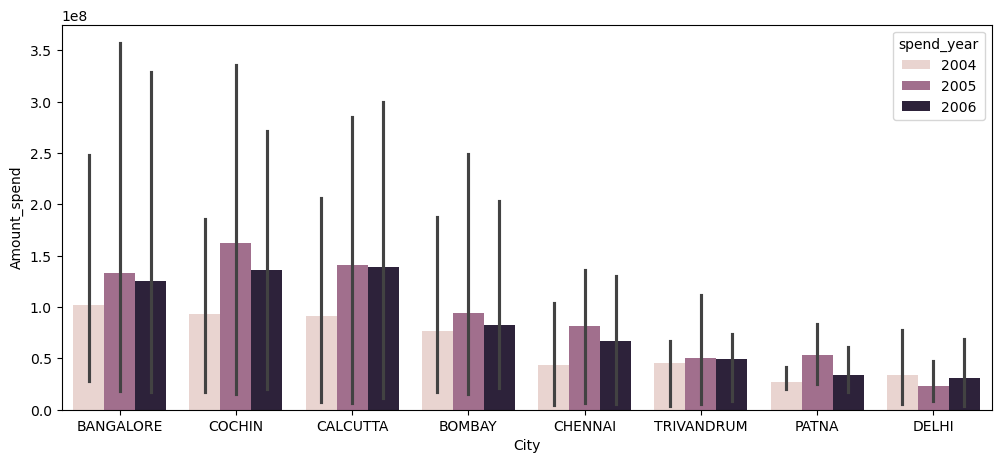

In [96]:
cust_repay_spend["spend_year"]=cust_repay_spend.Month_spend.dt.year

yearly_base=cust_repay_spend.groupby(["City","spend_year","Product"])["Amount_spend"].sum().reset_index().sort_values("Amount_spend",ascending=False,ignore_index=True)

plt.figure(figsize=(12,5))
sns.barplot(data=yearly_base,x=yearly_base.City,y=yearly_base.Amount_spend,hue="spend_year")


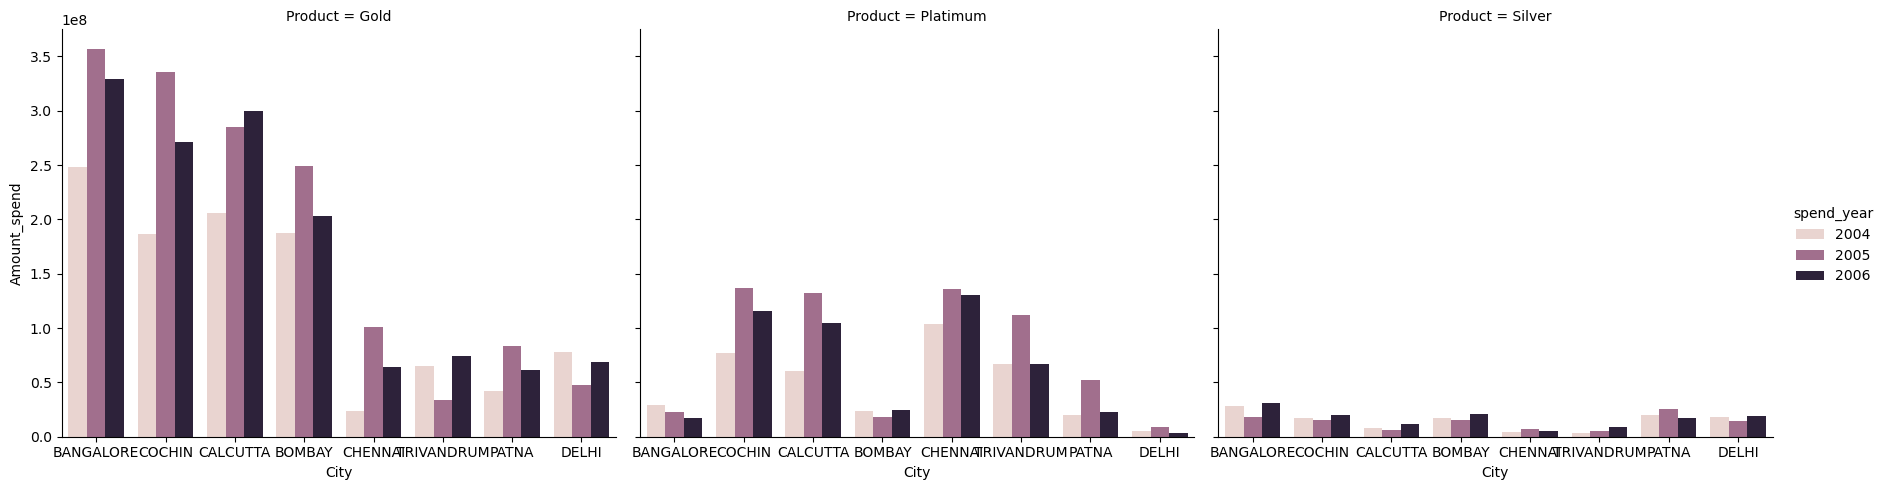

In [97]:
yearly_base = sns.catplot(
    data=yearly_base,
    x="City",
    y="Amount_spend",
    hue="spend_year",
    col="Product",
    kind="bar",
    height=5,
    aspect=1.2
)

## 4. Create graphs for
----------------------------------------------------------
## a. Monthly comparison of total spends, city wise


<Axes: xlabel='Spend_Month', ylabel='Amount_spend'>

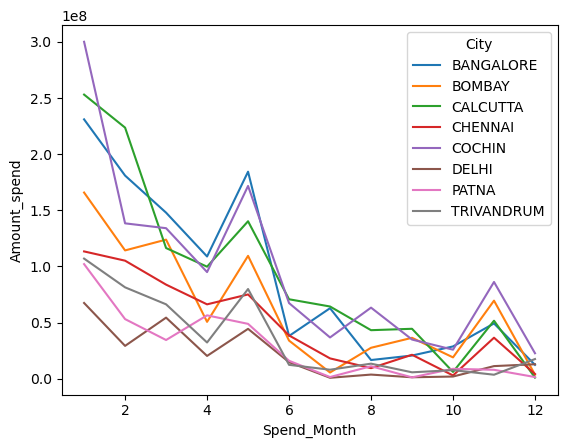

In [102]:
Monthly_comparison=cust_repay_spend.groupby(["Spend_Month","City"])["Amount_spend"].sum().reset_index()

sns.lineplot(data=Monthly_comparison,x=Monthly_comparison.Spend_Month,y=Monthly_comparison.Amount_spend,hue=Monthly_comparison.City)

## b. Comparison of yearly spend on air tickets


<Axes: xlabel='spend_year', ylabel='Amount_spend'>

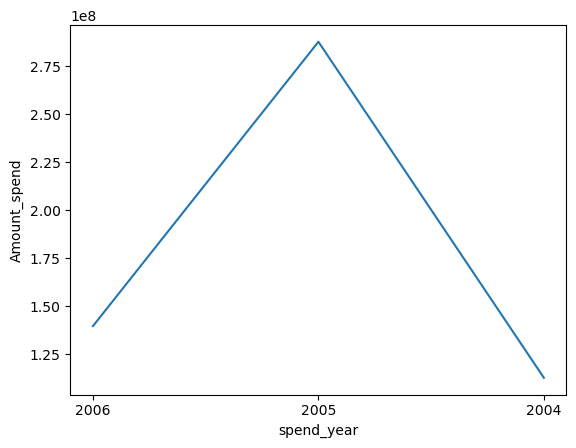

In [118]:
Air_ticket=cust_repay_spend.loc[cust_repay_spend.Type=="AIR TICKET"]
Yearly_spend_Air_ticket=Air_ticket.groupby("spend_year")["Amount_spend"].sum().reset_index().sort_values("spend_year",ascending=False).round({"Amount_spend":1})
Yearly_spend_Air_ticket["spend_year"]=Yearly_spend_Air_ticket.spend_year.astype(int).astype(str)

sns.lineplot(data=Yearly_spend_Air_ticket,x=Yearly_spend_Air_ticket.spend_year,y=Yearly_spend_Air_ticket.Amount_spend)

## c. Comparison of monthly spend for each product (look for any seasonality that exists in terms of spend)


<Axes: xlabel='Spend_Month', ylabel='Amount_spend'>

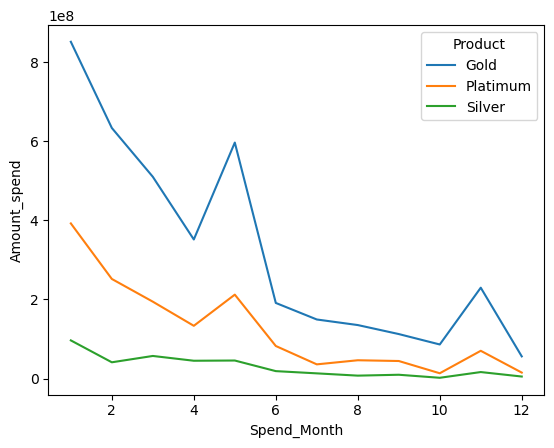

In [128]:
spen=cust_repay_spend.groupby(["Spend_Month","Product"])["Amount_spend"].sum().reset_index().round({"Amount_spend":1})


sns.lineplot(data=spen,x=spen.Spend_Month,y=spen.Amount_spend,hue=spen.Product)

## 5. Write user defined PYTHON function to perform the following analysis:
     You need to find top 10 customers for each city in terms of their repayment amount by 
     different products and by different time periods i.e. year or month. The user should be able 
     to specify the product (Gold/Silver/Platinum) and time period (yearly or monthly) and the 
     function should automatically take these inputs while identifying the top 10 customers

In [130]:
cust_repay_spend["Repayment_Month"]=cust_repay_spend.Month_repayment.dt.month
cust_repay_spend["Repayment_Year"]=cust_repay_spend.Month_repayment.dt.year

In [137]:
def top_10_customers(product, period):
    
    df = cust_repay_spend[
        cust_repay_spend["Product"].str.upper() == product.upper()
    ]
    
    if period.lower() == "yearly":
        
        result = (
            df.groupby(
                ["City","Customer","Repayment_Year"]
            )["Amount_repayment"]
            .sum()
            .reset_index()
        )
        
        result["Rank"] = (
            result.groupby("City")["Amount_repayment"]
            .rank(method="dense", ascending=False)
        )
        
    elif period.lower() == "monthly":
        
        result = (
            df.groupby(
                ["City","Customer","Repayment_Month"]
            )["Amount_repayment"]
            .sum()
            .reset_index()
        )
        
        result["Rank"] = (
            result.groupby("City")["Amount_repayment"]
            .rank(method="dense", ascending=False)
        )
        
    else:
        return "Choose yearly or monthly"
        
    
    return result[result["Rank"] <= 10].sort_values(
        ["City","Rank"]
    )

In [138]:
top_10_customers("Gold", "yearly")

,City,Customer,Repayment_Year,Amount_repayment,Rank
13,BANGALORE,A43,2005,1.242157e+08,1.0
4,BANGALORE,A13,2005,1.164879e+08,2.0
5,BANGALORE,A13,2006,1.077968e+08,3.0
6,BANGALORE,A14,2004,8.587810e+07,4.0
8,BANGALORE,A14,2006,8.311180e+07,5.0
14,BANGALORE,A43,2006,7.986894e+07,6.0
7,BANGALORE,A14,2005,7.725143e+07,7.0
3,BANGALORE,A13,2004,7.244740e+07,8.0
10,BANGALORE,A30,2005,7.202915e+07,9.0
11,BANGALORE,A30,2006,6.714788e+07,10.0
